In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

df = pd.read_csv('dataset2_top50_3pm_by_distance.csv')


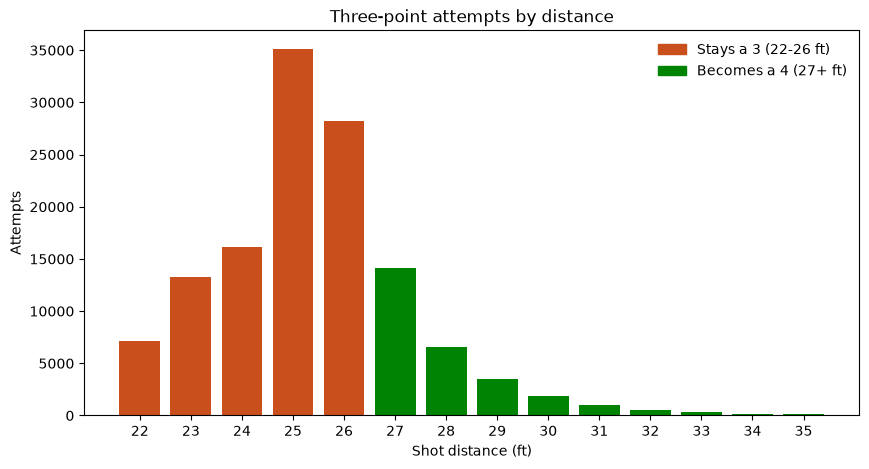

In [ ]:
#GRAPH: Number of three point attempts by distance

FOUR_PT_LINE = 27   
ORANGE = "#c94f1c"  
GREEN = "#008300" 

attempts = df.groupby("Shot Distance (ft)")["3PA"].sum()

attempts.index = attempts.index.astype(str)
distances = [str(d) for d in range(22, 36)]
attempts = attempts[distances]


colors = [GREEN if int(d) >= FOUR_PT_LINE else ORANGE for d in distances]

plt.figure(figsize=(10, 5))
plt.bar(distances, attempts, color=colors)
plt.legend(handles=[Patch(color=ORANGE, label="Stays a 3 (22-26 ft)"),
                    Patch(color=GREEN, label=f"Becomes a 4 ({FOUR_PT_LINE}+ ft)")],
           frameon=False)
plt.title("Three-point attempts by distance")
plt.xlabel("Shot distance (ft)")
plt.ylabel("Attempts")
plt.show()

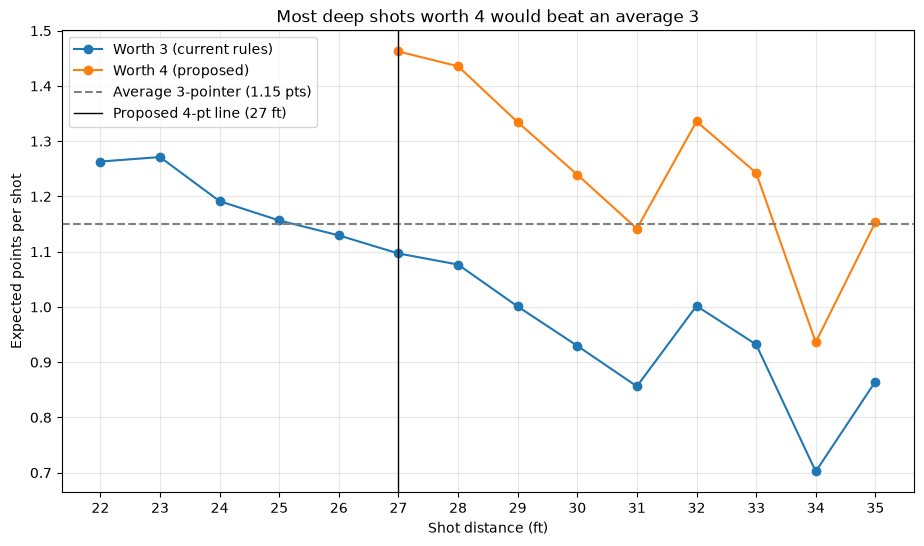

In [8]:
#GRAPH: Expected Points Per Shot for 3pt FG by dsitance and proposed 4pt

FOUR_PT_LINE = 27  # proposed 4-point distance (ft)

# Drop the "40+" heaves and make distance a number
shots = df[df["Shot Distance (ft)"] != "40+"].copy()
shots["dist"] = shots["Shot Distance (ft)"].astype(int)
shots = shots[(shots["dist"] >= 22) & (shots["dist"] <= 35)]

# Make rate at each distance
by_dist = shots.groupby("dist")[["3PM", "3PA"]].sum()
by_dist["pct"] = by_dist["3PM"] / by_dist["3PA"]

# Expected points per shot
worth3 = 3 * by_dist["pct"]
worth4 = 4 * by_dist["pct"][by_dist.index >= FOUR_PT_LINE]
avg3 = 3 * shots["3PM"].sum() / shots["3PA"].sum()

# Plot
plt.figure(figsize=(11, 6))
plt.plot(worth3.index, worth3, marker="o", label="Worth 3 (current rules)")
plt.plot(worth4.index, worth4, marker="o", label="Worth 4 (proposed)")
plt.axhline(avg3, color="gray", linestyle="--", label=f"Average 3-pointer ({avg3:.2f} pts)")
plt.axvline(FOUR_PT_LINE, color="black", linewidth=1, label=f"Proposed 4-pt line ({FOUR_PT_LINE} ft)")

plt.title("Most deep shots worth 4 would beat an average 3")
plt.xlabel("Shot distance (ft)")
plt.ylabel("Expected points per shot")
plt.xticks(range(22, 36))
plt.grid(alpha=0.3)
plt.legend()
plt.show()